# Дифференциация торговых центров по административным округам Москвы #

## О проекте ##
В качестве темы для проекта я взял часть моей курсовой работы, связанной с изучением дифференциации и динамики структуры торговых центров по административным округам Москвы. На данный момент при работе с существующими источниками по теме, я не нашел необходимых мне графических визуализаций данным по ТЦ. Соотвестенно целью проекта является создание необходимых для курсовой работы графиков, диаграмм, которые в дальнейшем будут использоваться при написании работы.

## Данные

В качестве основного датасета был использован csv-файл с данными о торговых центрах Москвы. В нем перечислены: названия ТЦ, координаты, адрес (при наличии), принадлежность к АО. Данные были получены через парсинг OpenStreetMap с помощью API Overpass.

Дополнительные данные:
- Датасет с более подробной информацией по выборке из 60 торговых центров (также данные по площади и году постройки ТЦ) - скомпилирован из отчетов по недвижимости и сайтов ТЦ с помощью ИИ.
- Данные о численности населения автономных округов (Мосгорстат, 2024)

## Ограничения данных

Прежде чем строить графики и диаграммы, стоит упомянуть ограничения, которые накладывают сами данные.
Во-первых, удалось спарсить лишь данные по округам в пределах МКАД. С одной стороны, это интересно наблюдение, что в OSM данные по ТЦ в ЗелАО и ТиНАО не размечены (теги ставятся на отдельные магазины). С другой стороны, отсутствие трех округов нарушает целостность исследования. Для дальнейшей работы с курсовой либо необходимо найти данные по округам из других источников, либо немного менять логику и структуру исследования
Во-вторых нужно упомянуть, что в основном датасете представлены, строго говоря, не все торговые центры. Мелкие пассажи, дома быта и т.д. не отмечены на OSM и не включаются при парсинге. Другое дело, что как в этом проекте, так и в курсовой работе, нас не интересует мелкие объекты торговли, внимание уделяется в основном крупным и средним ТЦ.

## Построение графиков

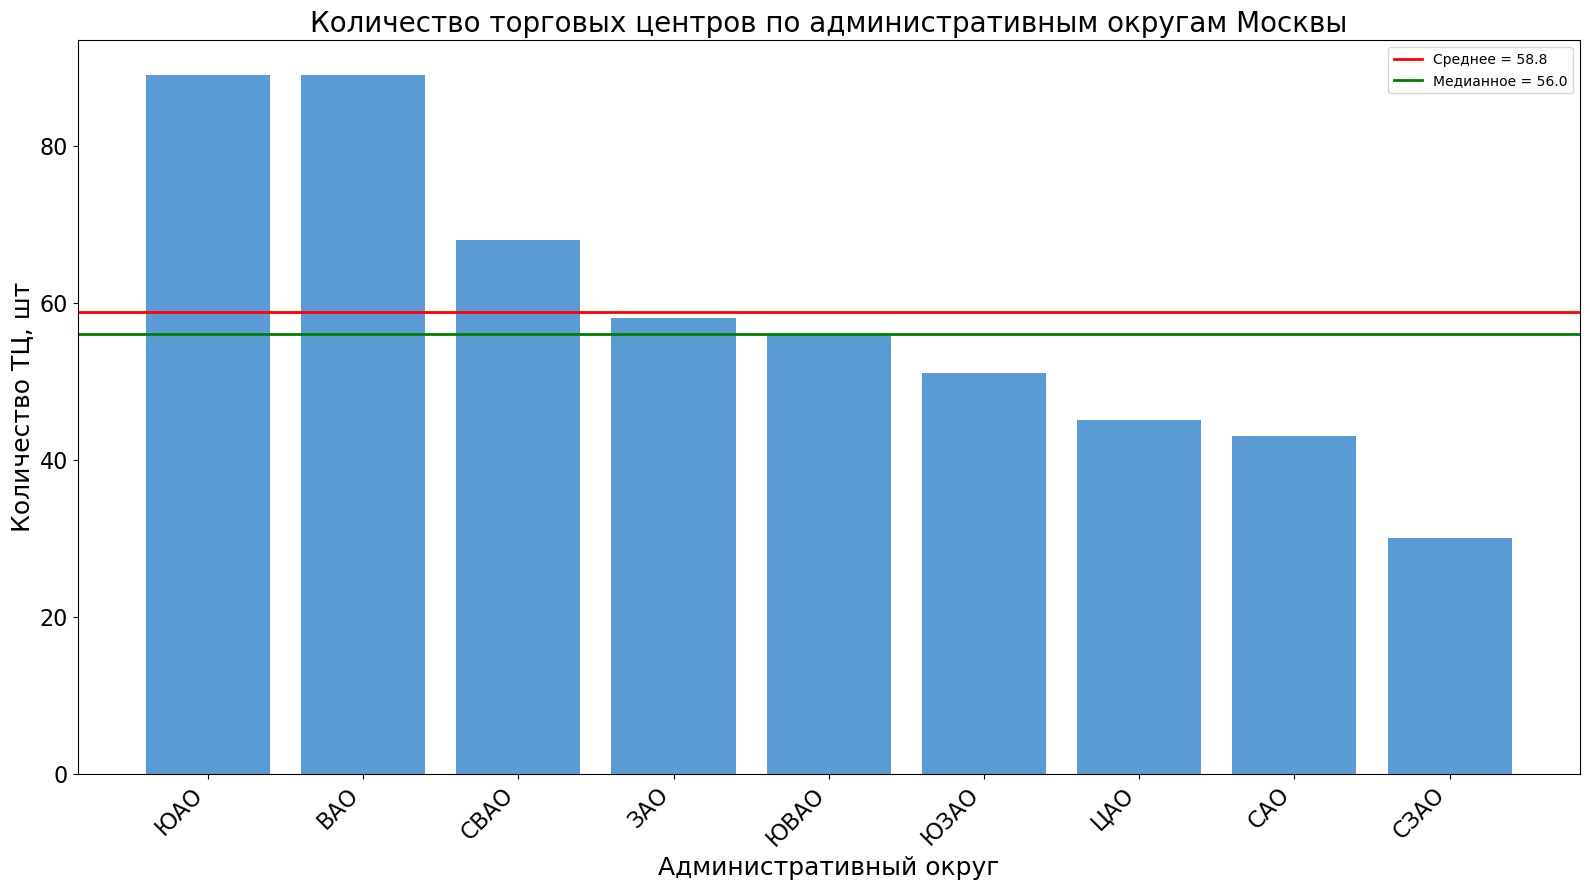

In [28]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import csv

with open('moscow_malls_osm.csv', encoding='utf-8-sig', newline='') as f:
    reader = csv.DictReader(f, delimiter=';')
    districts = [row['district'] for row in reader if row.get('district')] # считываем csv именно по разделителю точка с запятой, т.к. я разделял в Excel текс  по столбцам
   

counts = {}
for d in districts:
    if d not in counts.keys():    # Считаем количество для округа
        counts[d] = 1
    else:
        counts[d] += 1
item = sorted(counts.items(), key=lambda x: x[1], reverse=True) # Сортировка
x, y = zip(*item)
mean_value, median_value = np.mean(y), np.median(y) # Считаем среднее и медианное

#Построение графика
plt.figure(figsize=(16, 9))
plt.bar(x, y, color='#5B9BD5')
plt.axhline(mean_value, color='red', linewidth=2, label=f'Среднее = {mean_value:.1f}')
plt.axhline(median_value, color='green', linewidth=2, label=f'Медианное = {median_value:.1f}')
plt.title('Количество торговых центров по административным округам Москвы', fontsize=20)
plt.xlabel('Административный округ', fontsize=18)
plt.ylabel('Количество ТЦ, шт', fontsize=18)
plt.xticks(rotation=45, ha='right')
plt.tick_params(labelsize=16)
plt.legend()
plt.tight_layout()
plt.savefig(r'C:\Users\Admin\Desktop\geohse-python-main\graph1.png', dpi=300)

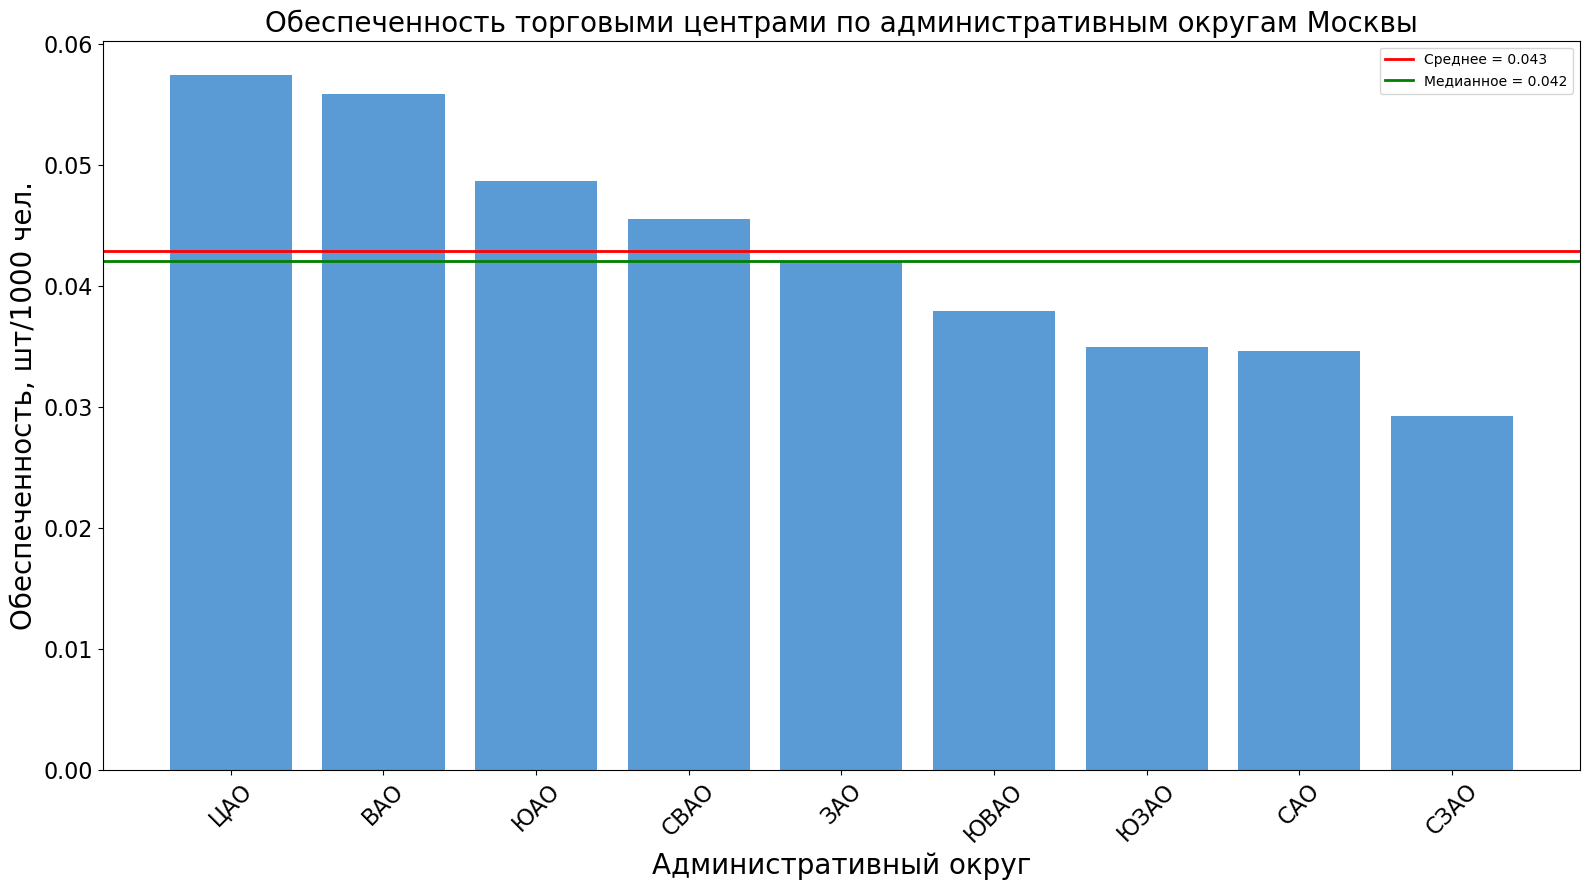

In [29]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import csv
population = pd.DataFrame([
    ("ЦАО", 784), ("САО", 1242), ("СВАО", 1493), ("ВАО", 1593),
    ("ЮВАО", 1478), ("ЮАО", 1830), ("ЮЗАО", 1458), ("ЗАО", 1378),
    ("СЗАО", 1027), ("ЗелАО", 257), ("НАО", 423), ("ТАО", 207),
], columns=["district", "pop_thousand"]) # Мосгорстат, 2024

df = pd.DataFrame(list(counts.items()), columns=['district', 'count'])   #Приводим словарь к массиву pandas
merged_df = pd.merge(population, df, on='district')                      # Соединями массивы по округу
merged_df['result'] = merged_df['count'] / merged_df['pop_thousand']     # Записываем обеспеченность в result
merged_df = merged_df.sort_values(by='result', ascending=False)          # Соритируем по result для красоты барплота
mean_value, median_value = np.mean(merged_df['result']), np.median(merged_df['result'])

# Строим барплот
plt.figure(figsize=(16, 9))
plt.bar(merged_df['district'], merged_df['result'], color='#5B9BD5')
plt.axhline(mean_value, color='red', linewidth=2, label=f'Среднее = {mean_value:.3f}')
plt.axhline(median_value, color='green', linewidth=2, label=f'Медианное = {median_value:.3f}') # в конце обрезаем дробную часть 
plt.title('Обеспеченность торговыми центрами по административным округам Москвы', fontsize=20)
plt.xlabel('Административный округ', fontsize=20)
plt.ylabel('Обеспеченность, шт/1000 чел.', fontsize=20)
plt.xticks(rotation=45)
plt.tick_params(labelsize=16)
plt.legend()
plt.tight_layout()
plt.savefig(r'C:\Users\Admin\Desktop\geohse-python-main\graph2.png', dpi=300)

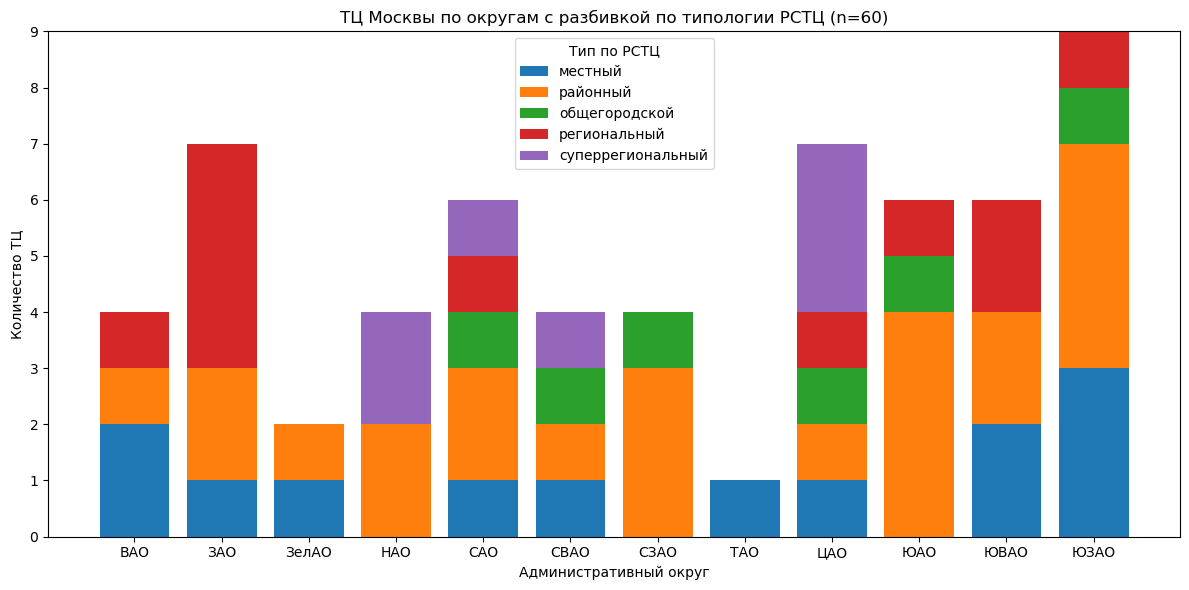

In [26]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import csv
from collections import Counter

with open('moscow_malls_dataset.csv', encoding='utf-8-sig') as f:
    data1 = list(csv.DictReader(f))

pairs = Counter((r['district'], r['type_rstc']) for r in data1) # подсчет уникальных пар "округ-тип"

districts = sorted({d for d, t in pairs})
types = ['местный', 'районный', 'общегородской', 'региональный', 'суперрегиональный']

values = {}
for t in types:     # делаем матрицу: для каждого типа - список количеств по округам
    values[t] = []
    for d in districts:
        values[t].append(pairs.get((d, t), 0))

        
# Рисуем диаграмму
bottom = np.zeros(len(districts))

plt.figure(figsize=(12, 6))
for t in types: # рисуем послойно, по каждому типу диаграмму
    plt.bar(districts, values[t], bottom=bottom, label=t)
    bottom += np.array(values[t])           # поднимаем нижнюю границу для следующего слоя

plt.xlabel('Административный округ')
plt.ylabel('Количество ТЦ')
plt.title('ТЦ Москвы по округам с разбивкой по типологии РСТЦ (n=60)')
plt.legend(title='Тип по РСТЦ')
plt.tight_layout()
plt.savefig(r'C:\Users\Admin\Desktop\geohse-python-main\graph3.png', dpi=300)

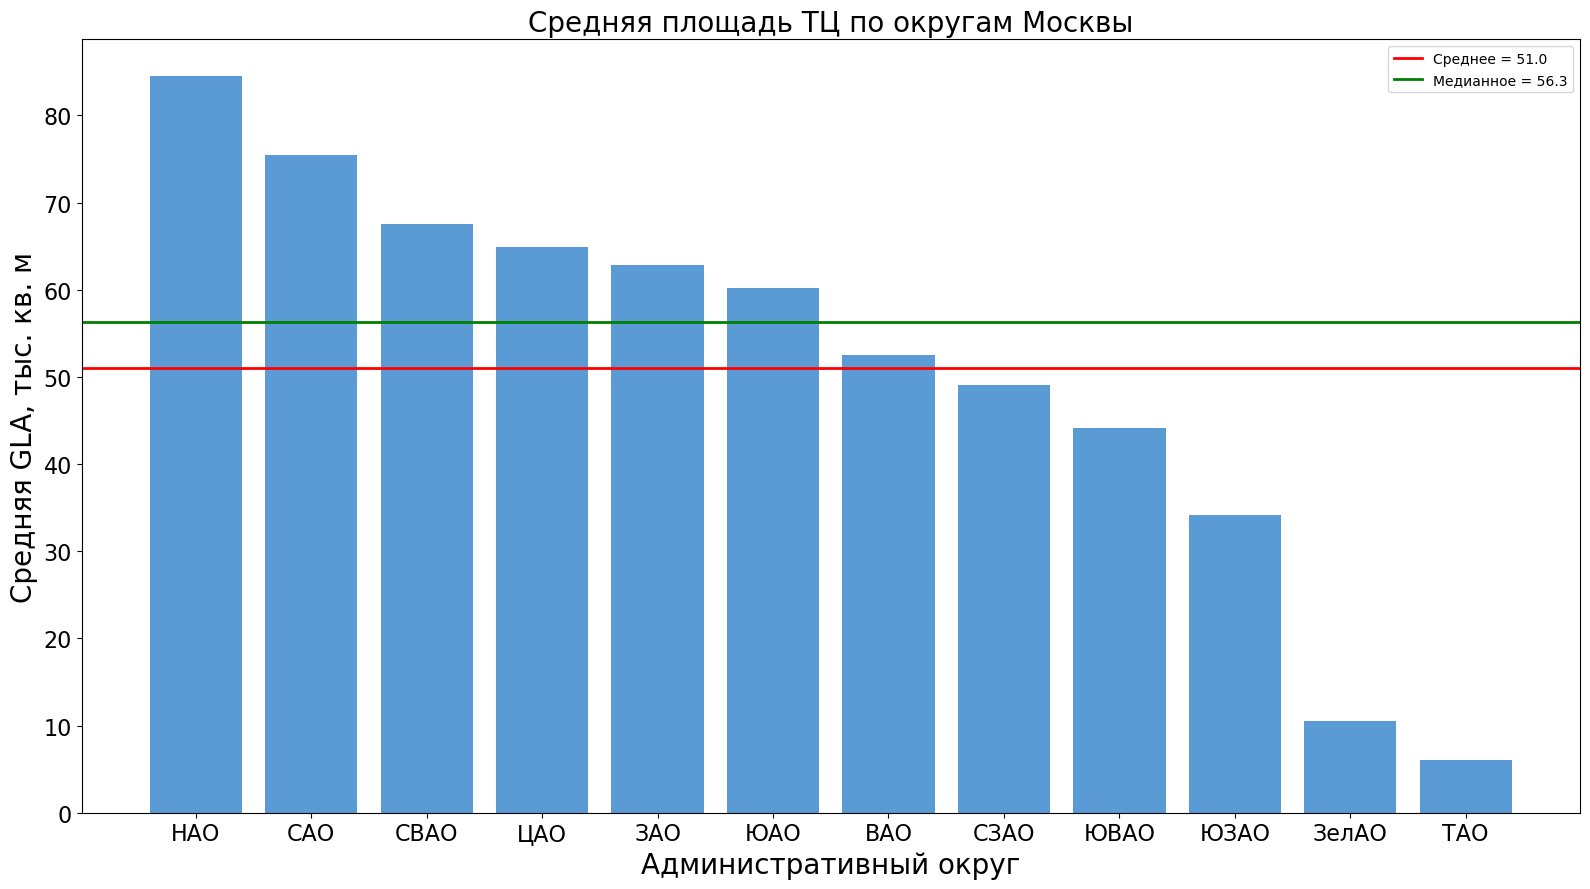

In [27]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import csv
sums = {}
counts = {}
for r in data1:                                           # считаем сумму площадей и кол-во объектов 
    if r['district'] in sums:
        sums[r['district']] += float(r['gla_k_sqm'])
        counts[r['district']] += 1
    else:
        sums[r['district']] = float(r['gla_k_sqm'])
        counts[r['district']] = 1

districts = sorted(sums, key=lambda x: sums[x] / counts[x], reverse=True) # сортируем, чтобы столбики шли от большего к меньшему
avg_gla = [sums[d] / counts[d] for d in districts]    # средняя плоащдь
mean_value, median_value = np.mean(avg_gla), np.median(avg_gla)

plt.figure(figsize=(16, 9))
plt.bar(districts, avg_gla, color='#5B9BD5')
plt.axhline(mean_value, color='red', linewidth=2, label=f'Среднее = {mean_value:.1f}')
plt.axhline(median_value, color='green', linewidth=2, label=f'Медианное = {median_value:.1f}')
plt.xlabel('Административный округ', fontsize=20)
plt.ylabel('Средняя GLA, тыс. кв. м', fontsize=20)
plt.title('Средняя площадь ТЦ по округам Москвы', fontsize=20)
plt.tick_params(labelsize=16)
plt.legend()
plt.tight_layout()
plt.savefig(r'C:\Users\Admin\Desktop\geohse-python-main\graph4.png', dpi=300)

## Выводы ##

По итогам анализа графиков можно сделать несколько выводов:
1. Графики имеют существенные ограничения, связанные с источником данных - OSM. В данных OSM нет целостной информации по ТЦ в ЗелАО и ТиНАО.
2. Распределение ТЦ по округам крайне неравномерно: лидеры (ЮАО и ВАО) превышают аутсайдера (СЗАО) почти в три раза.
3. Структура крупных ТЦ по типологии РСТЦ подтверждает центростремительную модель: ЦАО концентрирует суперрегиональные форматы, в то время как периферийные территории в большей мере представлены преимущественно районными центрами.